# Walmart Store Sales Forecasting 

## Project Overview

### Objective

Forecast **weekly sales** for Walmart stores and departments using historical sales patterns, economic indicators, promotions (markdowns), and holiday effects.

### Business Value

Accurate demand forecasting helps improve:

* inventory allocation
* staffing plans
* promotional planning
* supply chain optimization

#### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder

from xgboost import XGBRegressor

import plotly.express as px
import plotly.graph_objects as go

#### Load Data

In [2]:
train = pd.read_csv("C:\\Users\\User\\OneDrive\\Documents\\Data Science\\New Datasets\\Walmart Sales\\train.csv")
test = pd.read_csv("C:\\Users\\User\\OneDrive\\Documents\\Data Science\\New Datasets\\Walmart Sales\\test.csv")
features = pd.read_csv("C:\\Users\\User\\OneDrive\\Documents\\Data Science\\New Datasets\\Walmart Sales\\features.csv")
stores = pd.read_csv("C:\\Users\\User\\OneDrive\\Documents\\Data Science\\New Datasets\\Walmart Sales\\stores.csv")

In [3]:
print(train.shape, test.shape, features.shape, stores.shape)
train.head()

(421570, 5) (115064, 4) (8190, 12) (45, 3)


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [4]:
train.info()
test.info()
features.info()
stores.info()

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  str    
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  bool   
dtypes: bool(1), float64(1), int64(2), str(1)
memory usage: 17.3 MB
<class 'pandas.DataFrame'>
RangeIndex: 115064 entries, 0 to 115063
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   Store      115064 non-null  int64
 1   Dept       115064 non-null  int64
 2   Date       115064 non-null  str  
 3   IsHoliday  115064 non-null  bool 
dtypes: bool(1), int64(2), str(1)
memory usage: 3.8 MB
<class 'pandas.DataFrame'>
RangeIndex: 8190 entries, 0 to 8189
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 

In [5]:
train["Date"] = pd.to_datetime(train["Date"])
test["Date"] = pd.to_datetime(test["Date"])
features["Date"] = pd.to_datetime(features["Date"])

train.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [6]:
features.head()

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


In [7]:
stores.head()

,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


#### Merge Tables

In [8]:
train_merged = train.merge(features, on=["Store", "Date", "IsHoliday"], how="left")
train_merged = train_merged.merge(stores, on="Store", how="left")

test_merged = test.merge(features, on=["Store", "Date", "IsHoliday"], how="left")
test_merged = test_merged.merge(stores, on="Store", how="left")

train_merged.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,A,151315


In [9]:
test_merged.head()

,Store,Dept,Date,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,1,2012-11-02,False,55.32,3.386,6766.44,5147.70,50.82,3639.90,2737.42,223.462779,6.573,A,151315
1,1,1,2012-11-09,False,61.24,3.314,11421.32,3370.89,40.28,4646.79,6154.16,223.481307,6.573,A,151315
2,1,1,2012-11-16,False,52.92,3.252,9696.28,292.10,103.78,1133.15,6612.69,223.512911,6.573,A,151315
3,1,1,2012-11-23,True,56.23,3.211,883.59,4.17,74910.32,209.91,303.32,223.561947,6.573,A,151315
4,1,1,2012-11-30,False,52.34,3.207,2460.03,NaN,3838.35,150.57,6966.34,223.610984,6.573,A,151315


#### Handling Missing Values

Markdown columns represent promotions; missing often means no promotion.

In [10]:
train_merged.isna().sum()

Store                0
Dept                 0
Date                 0
Weekly_Sales         0
IsHoliday            0
Temperature          0
Fuel_Price           0
MarkDown1       270889
MarkDown2       310322
MarkDown3       284479
MarkDown4       286603
MarkDown5       270138
CPI                  0
Unemployment         0
Type                 0
Size                 0
dtype: int64

In [11]:
markdown_cols = ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]

for col in markdown_cols:
    train_merged[col] = train_merged[col].fillna(0)
    test_merged[col] = test_merged[col].fillna(0)

In [12]:
# Fill economic indicators within each store

fill_cols = ["CPI", "Unemployment", "Fuel_Price", "Temperature"]

train_merged = train_merged.sort_values(["Store", "Date"])
test_merged = test_merged.sort_values(["Store", "Date"])

for col in fill_cols:
    train_merged[col] = train_merged.groupby("Store")[col].ffill().bfill()
    test_merged[col] = test_merged.groupby("Store")[col].ffill().bfill()

### Exploratory Data Analysis (EDA)

#### Total Weekly Sales Trend

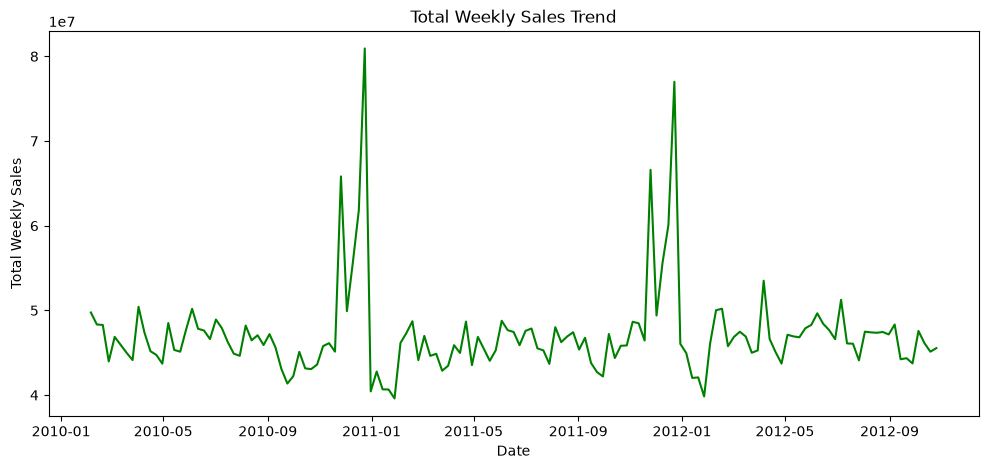

In [13]:
sales_trend = train_merged.groupby("Date")["Weekly_Sales"].sum().reset_index()

plt.figure(figsize=(12,5))
plt.plot(sales_trend["Date"], sales_trend["Weekly_Sales"], color="green")
plt.title("Total Weekly Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.show()

#### Holiday Effect

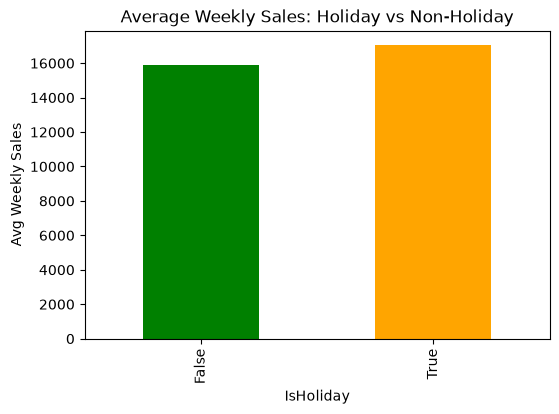

In [14]:
holiday_sales = train_merged.groupby("IsHoliday")["Weekly_Sales"].mean()

plt.figure(figsize=(6,4))
holiday_sales.plot(kind="bar", color=["green", "orange"])
plt.title("Average Weekly Sales: Holiday vs Non-Holiday")
plt.ylabel("Avg Weekly Sales")
plt.show()

#### Store Type Sales Comparison

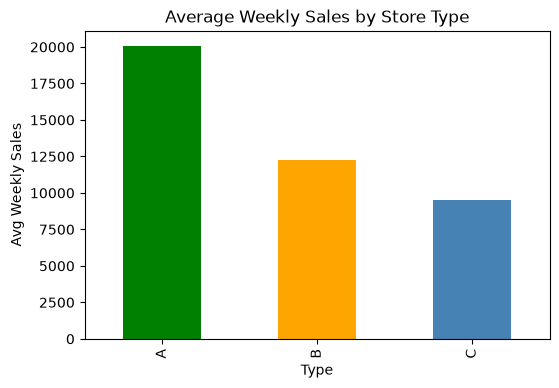

In [15]:
type_sales = train_merged.groupby("Type")["Weekly_Sales"].mean()

plt.figure(figsize=(6,4))
type_sales.plot(kind="bar", color=["green", "orange", "steelblue"])
plt.title("Average Weekly Sales by Store Type")
plt.ylabel("Avg Weekly Sales")
plt.show()

#### Feature Engineering

In [16]:
#Create Date Features

def create_date_features(df):
    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month
    df["Week"] = df["Date"].dt.isocalendar().week.astype(int)
    df["Quarter"] = df["Date"].dt.quarter
    return df

train_merged = create_date_features(train_merged)
test_merged = create_date_features(test_merged)

In [17]:
# Create Lag & Rolling Features (Store + Dept)

train_merged = train_merged.sort_values(["Store", "Dept", "Date"])

for lag in [1, 2, 4, 8]:
    train_merged[f"lag_{lag}"] = train_merged.groupby(["Store", "Dept"])["Weekly_Sales"].shift(lag)

for window in [4, 8, 12]:
    train_merged[f"roll_mean_{window}"] = (
        train_merged.groupby(["Store", "Dept"])["Weekly_Sales"]
        .shift(1)
        .rolling(window)
        .mean()
    )

lag_cols = [col for col in train_merged.columns if "lag_" in col or "roll_mean" in col]
train_merged[lag_cols] = train_merged[lag_cols].fillna(0)

train_merged.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,...,Month,Week,Quarter,lag_1,lag_2,lag_4,lag_8,roll_mean_4,roll_mean_8,roll_mean_12
0,1,1,2010-02-05,24924.50,False,42.31,2.572,0.0,0.0,0.0,...,2,5,1,0.00,0.00,0.0,0.0,0.00,0.0,0.0
1,1,1,2010-02-12,46039.49,True,38.51,2.548,0.0,0.0,0.0,...,2,6,1,24924.50,0.00,0.0,0.0,0.00,0.0,0.0
2,1,1,2010-02-19,41595.55,False,39.93,2.514,0.0,0.0,0.0,...,2,7,1,46039.49,24924.50,0.0,0.0,0.00,0.0,0.0
3,1,1,2010-02-26,19403.54,False,46.63,2.561,0.0,0.0,0.0,...,2,8,1,41595.55,46039.49,0.0,0.0,0.00,0.0,0.0
4,1,1,2010-03-05,21827.90,False,46.50,2.625,0.0,0.0,0.0,...,3,9,1,19403.54,41595.55,24924.5,0.0,32990.77,0.0,0.0


## Train/Validation Split (Time-Based)

We split based on time to avoid leakage.

In [18]:
cutoff_date = "2012-01-01"

train_data = train_merged[train_merged["Date"] < cutoff_date]
val_data = train_merged[train_merged["Date"] >= cutoff_date]

print(train_data.shape, val_data.shape)

(294132, 27) (127438, 27)


## Evaluation Metrics

In [20]:
print("Number of zero sales:",
      (train_data["Weekly_Sales"] == 0).sum())

print("Number of negative sales:",
      (train_data["Weekly_Sales"] < 0).sum())

print("Minimum sales:",
      train_data["Weekly_Sales"].min())

Number of zero sales: 55
Number of negative sales: 873
Minimum sales: -4988.94


since the data contains zero and negative sales values. RMSE, MAE, and R² are fine for evaluation, but MAPE can be unstable misleading even after aggregation. Thus, I've added Weighted Absolute Percentage Error (WAPE) because WAPE is much more appropriate for sales data containing zero and negative values.

In [21]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / (y_true + 1e-9))) * 100

def wape(y_true, y_pred):
    return (np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true))) * 100

def evaluate_model(y_true, y_pred, model_name):
    print(f"\n--- {model_name} ---")
    print("MAE:", mean_absolute_error(y_true, y_pred))
    print("RMSE:", rmse(y_true, y_pred))
    print("MAPE:", mape(y_true, y_pred))
    print("WAPE:", wape(y_true, y_pred))
    print("R²:", r2_score(y_true, y_pred))


## PART A: SARIMAX Forecasting (Aggregate Sales)

In [22]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarimax_df = train_merged.groupby("Date")["Weekly_Sales"].sum().reset_index()
sarimax_df = sarimax_df.set_index("Date")

sarimax_train = sarimax_df[sarimax_df.index < cutoff_date]
sarimax_val = sarimax_df[sarimax_df.index >= cutoff_date]

sarimax_model = SARIMAX(
    sarimax_train,
    order=(1,1,1),
    seasonal_order=(1,1,1,52)
)

sarimax_result = sarimax_model.fit(disp=False)

sarimax_forecast = sarimax_result.forecast(steps=len(sarimax_val))

evaluate_model(sarimax_val["Weekly_Sales"], sarimax_forecast, "SARIMAX")

C:\Users\User\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\User\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)



--- SARIMAX ---
MAE: 10570583.412906736
RMSE: 10893740.468239399
MAPE: 22.718831234790667
WAPE: 22.725244707129296
R²: -19.0044213165171


### Plot:

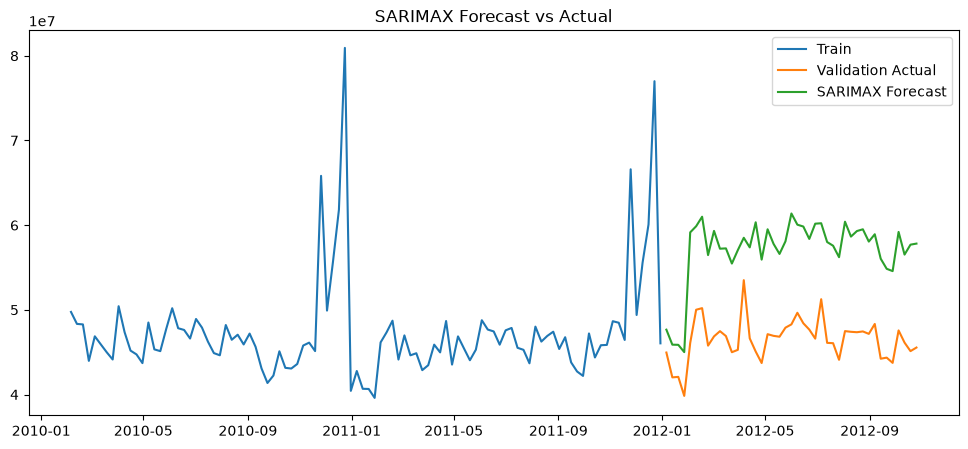

In [23]:
plt.figure(figsize=(12,5))
plt.plot(sarimax_train.index, sarimax_train["Weekly_Sales"], label="Train")
plt.plot(sarimax_val.index, sarimax_val["Weekly_Sales"], label="Validation Actual")
plt.plot(sarimax_val.index, sarimax_forecast, label="SARIMAX Forecast")
plt.title("SARIMAX Forecast vs Actual")
plt.legend()
plt.show()

## PART B: Prophet Forecasting

In [24]:
from prophet import Prophet

prophet_df = sarimax_df.reset_index()
prophet_df.columns = ["ds", "y"]

prophet_train = prophet_df[prophet_df["ds"] < cutoff_date]
prophet_val = prophet_df[prophet_df["ds"] >= cutoff_date]

prophet_model = Prophet(yearly_seasonality=True)
prophet_model.fit(prophet_train)

future = prophet_model.make_future_dataframe(periods=len(prophet_val), freq="W-FRI")
forecast = prophet_model.predict(future)

prophet_preds = forecast.iloc[-len(prophet_val):]["yhat"].values

evaluate_model(prophet_val["y"], prophet_preds, "Prophet")

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
13:52:07 - cmdstanpy - INFO - Chain [1] start processing
13:52:08 - cmdstanpy - INFO - Chain [1] done processing



--- Prophet ---
MAE: 1800569.3453739341
RMSE: 2423341.568588317
MAPE: 3.8499721988633175
WAPE: 3.870966945477835
R²: 0.010077471836390184


### Plot:

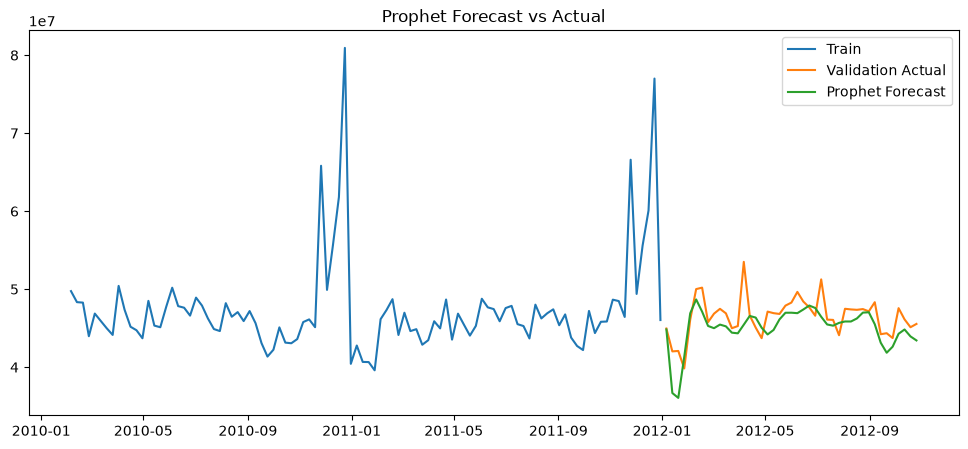

In [25]:
plt.figure(figsize=(12,5))
plt.plot(prophet_train["ds"], prophet_train["y"], label="Train")
plt.plot(prophet_val["ds"], prophet_val["y"], label="Validation Actual")
plt.plot(prophet_val["ds"], prophet_preds, label="Prophet Forecast")
plt.title("Prophet Forecast vs Actual")
plt.legend()

plt.savefig("prophet_forecast_vs_actual.png", dpi=300, bbox_inches="tight")

plt.show()


## PART C: XGBoost Forecasting (Store + Dept Level)

In [26]:
# Encode Store Type

ml_train = train_data.copy()
ml_val = val_data.copy()

le = LabelEncoder()
ml_train["Type"] = le.fit_transform(ml_train["Type"])
ml_val["Type"] = le.transform(ml_val["Type"])

In [27]:
# Select Features

target = "Weekly_Sales"

feature_cols = [
    "Store", "Dept", "IsHoliday", "Temperature", "Fuel_Price",
    "CPI", "Unemployment", "Size", "Type",
    "Year", "Month", "Week", "Quarter"
] + lag_cols

X_train = ml_train[feature_cols]
y_train = ml_train[target]

X_val = ml_val[feature_cols]
y_val = ml_val[target]


#### Baseline XGBoost Model

In [28]:
xgb_baseline = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb_baseline.fit(X_train, y_train)

baseline_preds = xgb_baseline.predict(X_val)

evaluate_model(y_val, baseline_preds, "XGBoost Baseline")


--- XGBoost Baseline ---
MAE: 1412.3164397934702
RMSE: 2977.2684174089804
MAPE: 2640955490.111862
WAPE: 8.998336362191644
R²: 0.9818846047702143


#### TimeSeriesSplit Cross-Validation

In [29]:
# We apply TimeSeriesSplit to prevent future leakage.

tscv = TimeSeriesSplit(n_splits=5)

cv_rmse_scores = []

for train_index, test_index in tscv.split(X_train):
    X_tr, X_te = X_train.iloc[train_index], X_train.iloc[test_index]
    y_tr, y_te = y_train.iloc[train_index], y_train.iloc[test_index]
    
    model = XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )
    
    model.fit(X_tr, y_tr)
    preds = model.predict(X_te)
    
    cv_rmse_scores.append(rmse(y_te, preds))

print("TimeSeriesSplit RMSE Scores:", cv_rmse_scores)
print("Average CV RMSE:", np.mean(cv_rmse_scores))

TimeSeriesSplit RMSE Scores: [np.float64(7113.21130173948), np.float64(4716.099217426114), np.float64(4740.15763230142), np.float64(4115.181085768586), np.float64(3742.8715470299926)]
Average CV RMSE: 4885.504156853119


#### Hyperparameter Tuning with RandomizedSearchCV

In [30]:
param_grid = {
    "n_estimators": [200, 400, 600, 800],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [4, 6, 8, 10],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0]
}

xgb_model = XGBRegressor(random_state=42)

random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    verbose=1,
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best CV RMSE:", -random_search.best_score_)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best Parameters: {'subsample': 0.8, 'n_estimators': 800, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.6}
Best CV RMSE: 4598.081488051128


#### Train Best Model + Evaluate on Validation Set

In [31]:
best_xgb = random_search.best_estimator_

best_xgb.fit(X_train, y_train)

tuned_preds = best_xgb.predict(X_val)

evaluate_model(y_val, tuned_preds, "XGBoost Tuned")


--- XGBoost Tuned ---
MAE: 1477.3319410389572
RMSE: 3093.427620350209
MAPE: 4895576937.648645
WAPE: 9.412571679773114
R²: 0.9804434721649463


In [33]:
xgb_results = ml_val[["Date"]].copy()

xgb_results["Actual"] = y_val.values
xgb_results["Predicted"] = tuned_preds

In [34]:
xgb_weekly = (
    xgb_results
    .groupby("Date")
    .sum()
    .reset_index()
)

In [35]:
print(len(xgb_weekly))

43


In [36]:
evaluate_model(
    xgb_weekly["Actual"],
    xgb_weekly["Predicted"],
    "XGBoost Aggregated"
)


--- XGBoost Aggregated ---
MAE: 1227583.9053488371
RMSE: 1752573.7360904065
MAPE: 2.60616327863541
WAPE: 2.6391300799465065
R²: 0.4822447133725263


#### Plot:

In [54]:
train_agg = (
    ml_train.groupby("Date")["Weekly_Sales"]
    .sum()
    .reset_index()
)

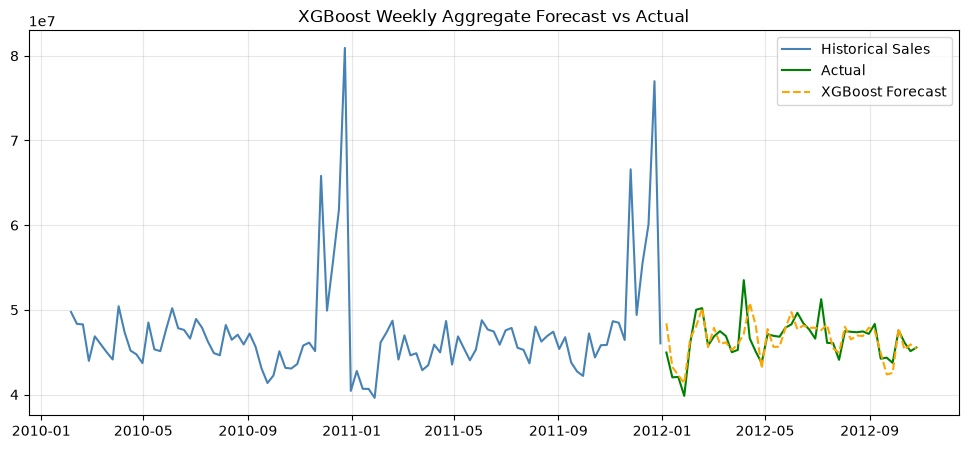

In [56]:
plt.figure(figsize=(12,5))

plt.plot(
    train_agg["Date"],
    train_agg["Weekly_Sales"],
    color="steelblue",
    label="Historical Sales"
)

plt.plot(
    xgb_weekly["Date"],
    xgb_weekly["Actual"],
    color="green",
    label="Actual"
)

plt.plot(
    xgb_weekly["Date"],
    xgb_weekly["Predicted"],
    color="orange",
    linestyle="--",
    label="XGBoost Forecast"
)

plt.legend()
plt.title("XGBoost Weekly Aggregate Forecast vs Actual")
plt.grid(alpha=0.3)
plt.savefig("xgboost_weekly_aggregate_forecast_vs_actual.png", dpi=300, bbox_inches="tight")
plt.show()

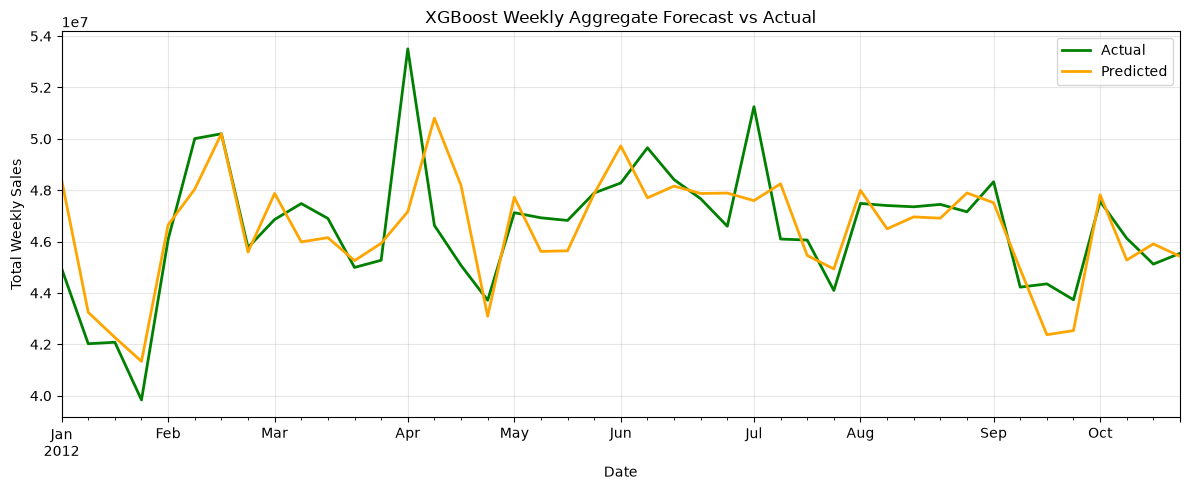

In [37]:
comparison = xgb_weekly.copy()

comparison.plot(
    x="Date",
    y=["Actual", "Predicted"],
    figsize=(12,5),
    color=["green", "orange"],
    linewidth=2)

plt.title("XGBoost Weekly Aggregate Forecast vs Actual")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("xgboost_weekly_aggregate_forecast.png", dpi=300, bbox_inches="tight")
plt.show()

### Model Comparison Summary Table

In [39]:
results = pd.DataFrame({
    "Model": ["SARIMAX", "Prophet", "XGBoost Aggregated"],
    "RMSE": [
        rmse(sarimax_val["Weekly_Sales"], sarimax_forecast),
        rmse(prophet_val["y"], prophet_preds),
        rmse(xgb_weekly["Actual"], xgb_weekly["Predicted"])
    ],
    "MAE": [
        mean_absolute_error(sarimax_val["Weekly_Sales"], sarimax_forecast),
        mean_absolute_error(prophet_val["y"], prophet_preds),
        mean_absolute_error(xgb_weekly["Actual"], xgb_weekly["Predicted"])
    ],
    "MAPE": [
        mape(sarimax_val["Weekly_Sales"], sarimax_forecast),
        mape(prophet_val["y"], prophet_preds),
        mape(xgb_weekly["Actual"], xgb_weekly["Predicted"])
    ],
    "WAPE": [
        wape(sarimax_val["Weekly_Sales"], sarimax_forecast),
        wape(prophet_val["y"], prophet_preds),
        wape(xgb_weekly["Actual"], xgb_weekly["Predicted"])
    ],
    "R2": [
        r2_score(sarimax_val["Weekly_Sales"], sarimax_forecast),
        r2_score(prophet_val["y"], prophet_preds),
        r2_score(xgb_weekly["Actual"], xgb_weekly["Predicted"])
    ]
})

results.sort_values("RMSE")

,Model,RMSE,MAE,MAPE,WAPE,R2
2,XGBoost Aggregated,1.752574e+06,1.227584e+06,2.606163,2.639130,0.482245
1,Prophet,2.423342e+06,1.800569e+06,3.849972,3.870967,0.010077
0,SARIMAX,1.089374e+07,1.057058e+07,22.718831,22.725245,-19.004421


**XGBoost Aggregated (Best Model)**

*RMSE = 1.75 million*
* Lowest RMSE of the three models.
* Indicates the smallest overall forecasting error.

*MAE = 1.23 million*
* On average, weekly forecasts miss actual sales by about 1.23 million.

*WAPE = 2.64%*
* This is excellent for retail forecasting.
* It means total forecast error is only about 2.64% of total sales.

*R² = 0.482*
* The model explains about 48.2% of the variation in weekly aggregate sales.
* Not perfect, but clearly useful.

**Prophet (Second Best)**

*RMSE = 2.42 million*
* Higher error than XGBoost.

*MAE = 1.80 million*
* Larger average forecasting error.

*WAPE = 3.87%*
* Still fairly good.
* Roughly 1.2 percentage points worse than XGBoost.

*R² = 0.01*
* Very weak explanatory power.
* Prophet is barely improving over a simple baseline.

**SARIMAX (Worst)**

*RMSE = 10.89 million*
* Extremely large errors relative to the other models.

*MAE = 10.57 million*
* Average forecast misses by over 10 million.

*WAPE = 22.73%*
* Nearly a quarter of total sales volume represented as error.

*R² = -19.00*
* This is a major red flag. Negative R² means SARIMAX is performing substantially worse than simply predicting the average weekly sales every week.

Following aggregation of Store-Department forecasts to the weekly sales level, the tuned XGBoost model achieved the best performance with an RMSE of 1.75 million, MAE of 1.23 million, WAPE of 2.64%, and R² of 0.482. Prophet ranked second with a WAPE of 3.87%, while SARIMAX performed poorly, producing a WAPE of 22.73% and a negative R² value. These results indicate that the XGBoost model was the most effective at capturing sales patterns and generating accurate forecasts for Walmart weekly sales.

#### Error Analysis by Store Type

In [40]:
ml_val_copy = ml_val.copy()
ml_val_copy["Predicted_Sales"] = tuned_preds
ml_val_copy["Absolute_Error"] = np.abs(ml_val_copy["Weekly_Sales"] - ml_val_copy["Predicted_Sales"])

error_by_type = ml_val_copy.groupby("Type")["Absolute_Error"].mean().reset_index()
error_by_type

,Type,Absolute_Error
0,0,1776.665962
1,1,1279.154529
2,2,743.332745


#### Plot:

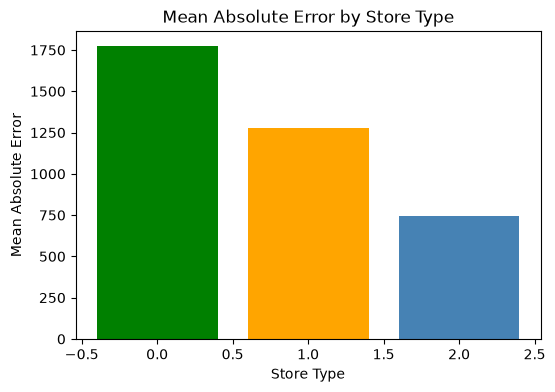

In [41]:
plt.figure(figsize=(6,4))
plt.bar(error_by_type["Type"], error_by_type["Absolute_Error"], color=["green", "orange", "steelblue"])
plt.title("Mean Absolute Error by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Mean Absolute Error")
plt.show()

#### Error Analysis by Department

In [42]:
error_by_dept = ml_val_copy.groupby("Dept")["Absolute_Error"].mean().reset_index()
error_by_dept = error_by_dept.sort_values("Absolute_Error", ascending=False)

error_by_dept.head(10)

,Dept,Absolute_Error
60,72,5588.720861
36,38,5585.668582
73,92,4968.878908
76,95,3720.521163
37,39,3654.195728
57,65,3520.971755
0,1,2935.336623
6,7,2873.251703
8,9,2739.698139
14,16,2727.722851


Plot top 15 worst departments:

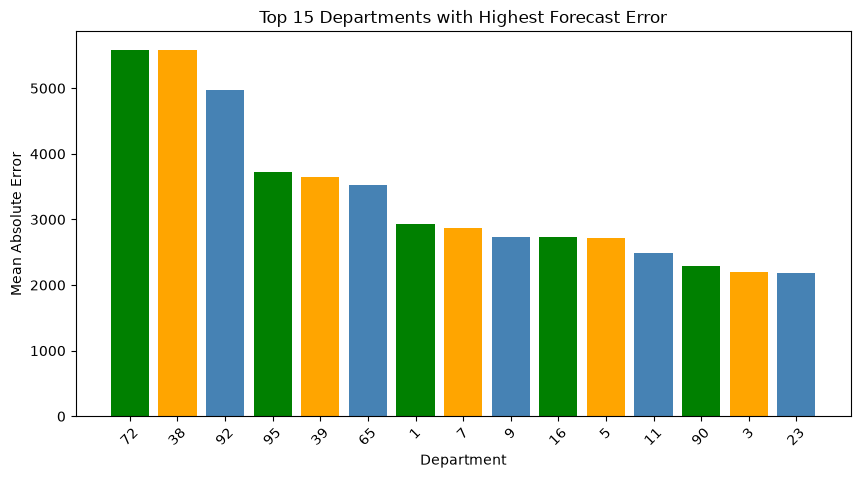

In [43]:
top_depts = error_by_dept.head(15)
colors = ["green", "orange", "steelblue"] * 5  # 15 colors

plt.figure(figsize=(10,5))
plt.bar(top_depts["Dept"].astype(str), top_depts["Absolute_Error"], color=colors)
plt.title("Top 15 Departments with Highest Forecast Error")
plt.xlabel("Department")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=45)
plt.show()

### Interactive Plotly Dashboard

#### Sales Trend Dashboard

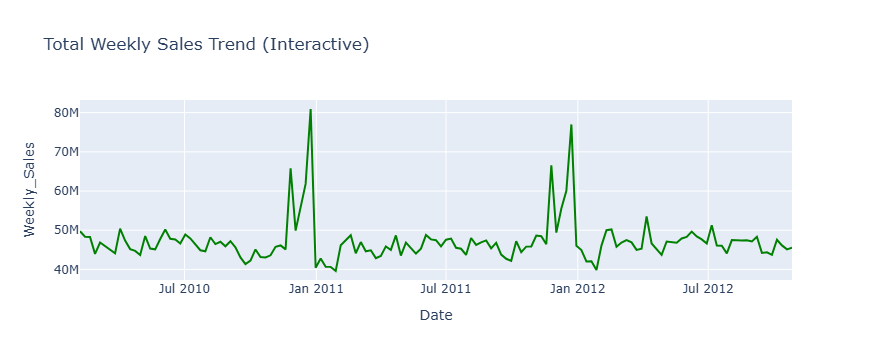

In [44]:
fig = px.line(
    sales_trend,
    x="Date",
    y="Weekly_Sales",
    title="Total Weekly Sales Trend (Interactive)"
)

fig.update_traces(line_color="green")
fig.show()

#### Holiday Sales Dashboard

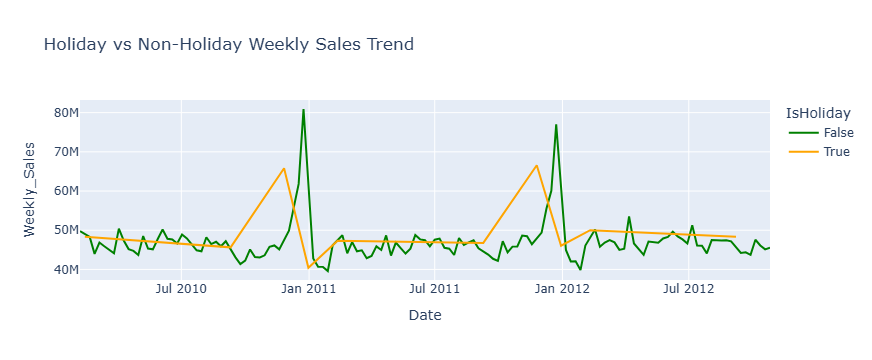

In [45]:
holiday_df = train_merged.groupby(["Date", "IsHoliday"])["Weekly_Sales"].sum().reset_index()

fig = px.line(
    holiday_df,
    x="Date",
    y="Weekly_Sales",
    color="IsHoliday",
    title="Holiday vs Non-Holiday Weekly Sales Trend",
    color_discrete_map={
        False: "green",
        True: "orange"}
)

fig.show()

#### Store Type Sales Dashboard

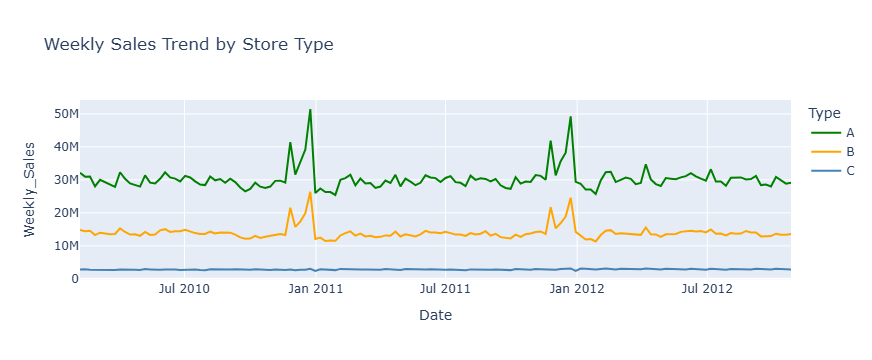

In [46]:
type_df = train_merged.groupby(["Date", "Type"])["Weekly_Sales"].sum().reset_index()

fig = px.line(
    type_df,
    x="Date",
    y="Weekly_Sales",
    color="Type",
    title="Weekly Sales Trend by Store Type",
    color_discrete_map={
        "A": "green",
        "B": "orange",
        "C": "steelblue",}
)

fig.show()

#### Final Model Training on Full Dataset + Predict Test

In [47]:
# Create Lag/Roll Features for Full Data

full_data = pd.concat([train_merged, test_merged], axis=0, sort=False)
full_data = full_data.sort_values(["Store", "Dept", "Date"])

for lag in [1, 2, 4, 8]:
    full_data[f"lag_{lag}"] = full_data.groupby(["Store", "Dept"])["Weekly_Sales"].shift(lag)

for window in [4, 8, 12]:
    full_data[f"roll_mean_{window}"] = (
        full_data.groupby(["Store", "Dept"])["Weekly_Sales"]
        .shift(1)
        .rolling(window)
        .mean()
    )

full_data[lag_cols] = full_data[lag_cols].fillna(0)

Split back:

In [48]:
final_train = full_data[full_data["Weekly_Sales"].notnull()]
final_test = full_data[full_data["Weekly_Sales"].isnull()]

Encode store type:

In [49]:
final_train["Type"] = le.fit_transform(final_train["Type"])
final_test["Type"] = le.transform(final_test["Type"])

Train final model:

In [50]:
X_final_train = final_train[feature_cols]
y_final_train = final_train["Weekly_Sales"]

X_final_test = final_test[feature_cols]

best_xgb.fit(X_final_train, y_final_train)

test_preds = best_xgb.predict(X_final_test)

#### Submission File

In [51]:
submission = pd.DataFrame({
    "Id": test["Store"].astype(str) + "_" + test["Dept"].astype(str) + "_" + test["Date"].astype(str),
    "Weekly_Sales": test_preds
})

submission.to_csv("submission.csv", index=False)
submission.head()

,Id,Weekly_Sales
0,1_1_2012-11-02,29108.238281
1,1_1_2012-11-09,8294.311523
2,1_1_2012-11-16,12248.577148
3,1_1_2012-11-23,13313.377930
4,1_1_2012-11-30,13926.188477


In [52]:
print(xgb_weekly["Date"].min())
print(xgb_weekly["Date"].max())

2012-01-06 00:00:00
2012-10-26 00:00:00


In [53]:
print(sarimax_df.index.min())
print(sarimax_df.index.max())

2010-02-05 00:00:00
2012-10-26 00:00:00


# Conclusion 

### Key Findings

* Sales show strong seasonal peaks around holiday periods.
* Store size and promotional markdowns significantly impact weekly sales.
* XGBoost with lag and rolling features outperformed classical forecasting methods.

### Recommendation

XGBoost is the most effective model for store-department level forecasting due to its ability to model complex nonlinear patterns and incorporate external regressors.